In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df=pd.read_csv('/content/drive/MyDrive/titanic_toy.csv')

In [6]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [7]:
df.isnull().mean()

,0
Age,0.198653
Fare,0.050505
Family,0.000000
Survived,0.000000


In [8]:
X=df[['Age','Fare','Family']]
Y=df['Survived']

In [9]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2)

In [12]:
X_train['Age_99']=X_train['Age'].fillna(99)
X_train['Age_minus1']=X_train['Age'].fillna(-1)

X_train['Fare_999']=X_train['Fare'].fillna(999)
X_train['Fare_minus1']=X_train['Fare'].fillna(-1)

In [14]:
print("Variance of Age before Arbitrary Value Imputation ",X_train['Age'].var())
print("Variance of Age after Age_99 Value Imputation ",X_train['Age_99'].var())
print("Variance of Age after Age_minus1 Value Imputation ",X_train['Age_minus1'].var())

Variance of Age before Arbitrary Value Imputation  204.3495133904614
Variance of Age after Age_99 Value Imputation  951.7275570187172
Variance of Age after Age_minus1 Value Imputation  318.0896202624484


In [13]:
print("Variance of Fare before Arbitrary Value Imputation ",X_train['Fare'].var())
print("Variance of Fare after Fare_999 Value Imputation ",X_train['Fare_999'].var())
print("Variance of Fare after Fare_minus1 Value Imputation ",X_train['Fare_minus1'].var())

Variance of Fare before Arbitrary Value Imputation  2448.197913706318
Variance of Fare after Fare_999 Value Imputation  47219.20265217623
Variance of Fare after Fare_minus1 Value Imputation  2378.5676784883503


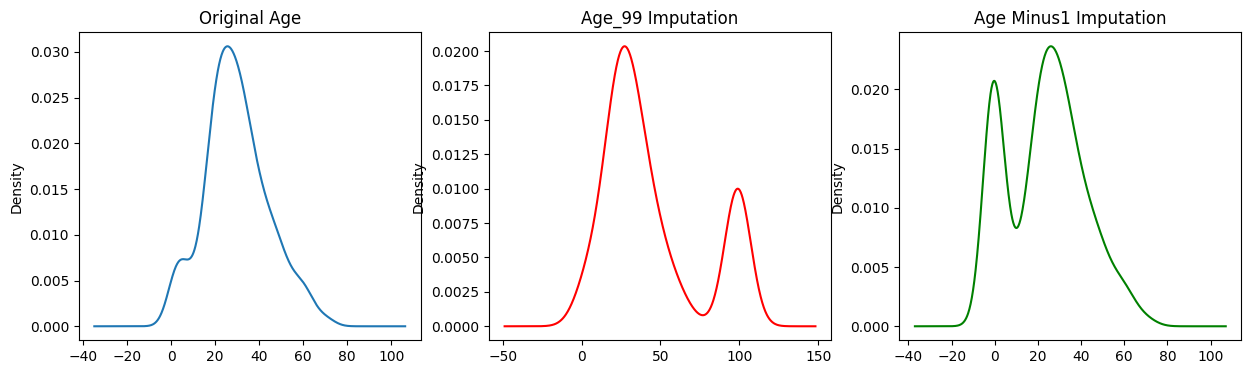

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
X_train['Age'].plot(kind='kde',ax=ax[0],title="Original Age")


X_train['Age_99'].plot(kind='kde',ax=ax[1],color='red',title='Age_99 Imputation')

X_train['Age_minus1'].plot(kind='kde',ax=ax[2],color='green',title='Age Minus1 Imputation')

plt.show()

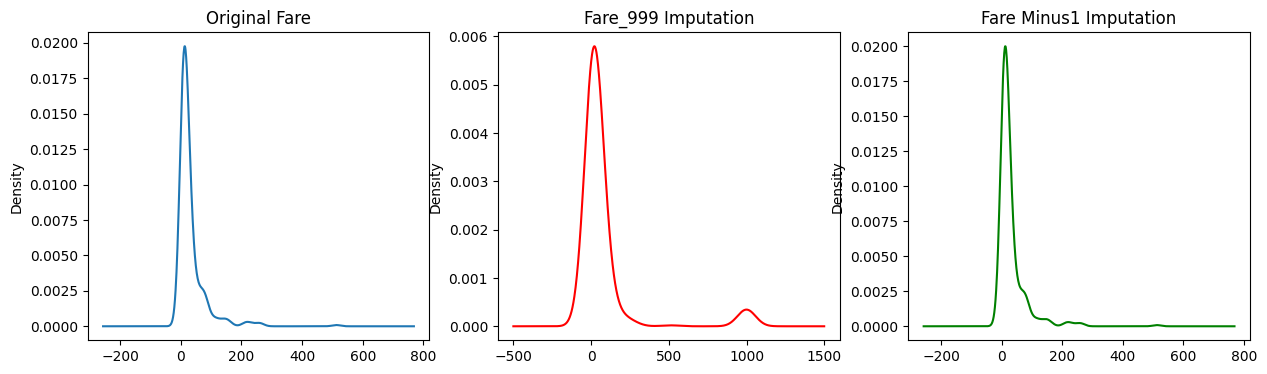

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
X_train['Fare'].plot(kind='kde',ax=ax[0],title="Original Fare")


X_train['Fare_999'].plot(kind='kde',ax=ax[1],color='red',title='Fare_999 Imputation')

X_train['Fare_minus1'].plot(kind='kde',ax=ax[2],color='green',title='Fare Minus1 Imputation')

plt.show()

In [19]:
X_train.cov()

,Age,Fare,Family,Age_99,Age_minus1,Fare_99,Fare_minus1,Fare_999
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,73.268412,63.321188,162.793430
Fare,70.719262,2448.197914,17.258917,-101.671097,125.558364,2448.197914,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-7.387287,-4.149246,16.051452,16.553989,11.528625
Age_99,204.349513,-101.671097,-7.387287,951.727557,-189.535540,-100.878826,-94.317400,-159.931663
Age_minus1,204.349513,125.558364,-4.149246,-189.535540,318.089620,128.692715,114.394141,257.379887
Fare_99,73.268412,2448.197914,16.051452,-100.878826,128.692715,2536.077343,2216.958409,5408.147749
Fare_minus1,63.321188,2448.197914,16.553989,-94.317400,114.394141,2216.958409,2378.567678,762.474982
Fare_999,162.793430,2448.197914,11.528625,-159.931663,257.379887,5408.147749,762.474982,47219.202652


In [20]:
X_train.corr()

,Age,Fare,Family,Age_99,Age_minus1,Fare_99,Fare_minus1,Fare_999
Age,1.000000,0.092644,-0.299113,1.000000,1.000000,0.095527,0.084585,0.051179
Fare,0.092644,1.000000,0.208268,-0.066273,0.142022,1.000000,1.000000,1.000000
Family,-0.299113,0.208268,1.000000,-0.144787,-0.140668,0.192723,0.205233,0.032079
Age_99,1.000000,-0.066273,-0.144787,1.000000,-0.344476,-0.064933,-0.062687,-0.023857
Age_minus1,1.000000,0.142022,-0.140668,-0.344476,1.000000,0.143284,0.131514,0.066411
Fare_99,0.095527,1.000000,0.192723,-0.064933,0.143284,1.000000,0.902648,0.494206
Fare_minus1,0.084585,1.000000,0.205233,-0.062687,0.131514,0.902648,1.000000,0.071946
Fare_999,0.051179,1.000000,0.032079,-0.023857,0.066411,0.494206,0.071946,1.000000


<Axes: >

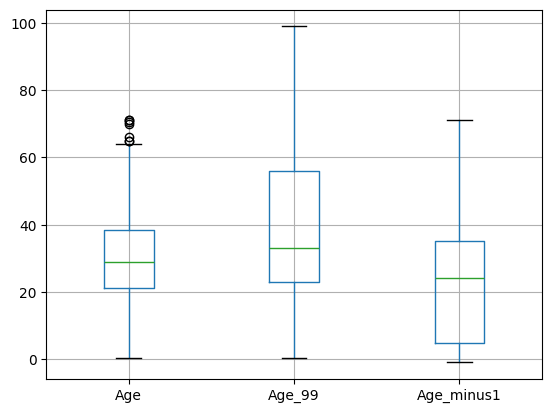

In [21]:
X_train[['Age','Age_99','Age_minus1']].boxplot()

<Axes: >

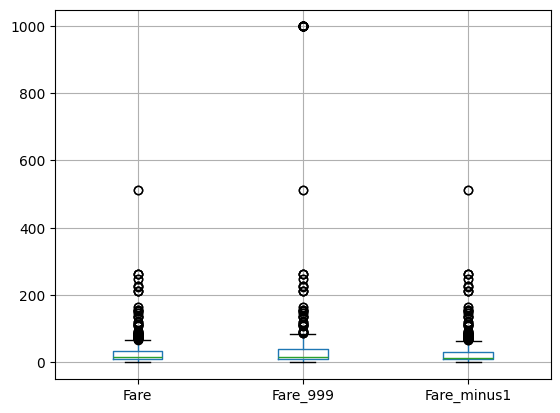

In [22]:
X_train[['Fare','Fare_999','Fare_minus1']].boxplot()

Using Sklearn

In [23]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2)

In [24]:
imputer1=SimpleImputer(strategy='constant',fill_value=99)
imputer2=SimpleImputer(strategy='constant',fill_value=999)

In [26]:
trf=ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare'])
],remainder='passthrough')

In [27]:
trf.fit(X_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1',
                                 SimpleImputer(fill_value=99,
                                               strategy='constant'),
                                 ['Age']),
                                ('imputer2',
                                 SimpleImputer(fill_value=999,
                                               strategy='constant'),
                                 ['Fare'])])

In [28]:
trf.named_transformers_['imputer1'].statistics_

array([99.])

In [29]:
trf.named_transformers_['imputer2'].statistics_

array([999.])

In [30]:
X_train=trf.transform(X_train)
X_test=trf.transform(X_test)

In [31]:
X_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 99.    , 221.7792,   0.    ],
       [ 99.    ,  25.925 ,   0.    ]])

In [32]:
X_test

array([[4.200000e+01, 2.628750e+01, 0.000000e+00],
       [2.100000e+01, 8.050000e+00, 0.000000e+00],
       [2.400000e+01, 6.500000e+01, 3.000000e+00],
       [2.800000e+01, 5.649580e+01, 0.000000e+00],
       [1.700000e+01, 7.925000e+00, 6.000000e+00],
       [3.000000e+01, 7.895800e+00, 0.000000e+00],
       [8.000000e+01, 3.000000e+01, 0.000000e+00],
       [2.500000e+01, 7.250000e+00, 0.000000e+00],
       [5.000000e+01, 1.336500e+02, 2.000000e+00],
       [2.500000e+01, 2.600000e+01, 1.000000e+00],
       [3.500000e+01, 2.600000e+01, 0.000000e+00],
       [3.500000e+01, 9.000000e+01, 1.000000e+00],
       [5.500000e+01, 1.600000e+01, 0.000000e+00],
       [9.900000e+01, 5.649580e+01, 0.000000e+00],
       [9.900000e+01, 5.649580e+01, 0.000000e+00],
       [1.900000e+01, 7.854200e+00, 1.000000e+00],
       [9.900000e+01, 1.524580e+01, 2.000000e+00],
       [4.900000e+01, 0.000000e+00, 0.000000e+00],
       [1.800000e+01, 9.990000e+02, 1.000000e+00],
       [6.500000e+01, 7.750000e